***LAKSHYA GARG E23CSEU1841***

In [14]:
import kagglehub
import os

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Dataset path:", path)

print(os.listdir(path))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia
['chest_xray']


In [15]:
train_dir = os.path.join(path, "chest_xray", "train")
test_dir = os.path.join(path, "chest_xray", "test")
val_dir = os.path.join(path, "chest_xray", "val")

print("Training folders:", os.listdir(train_dir))
print("Testing folders:", os.listdir(test_dir))
print("Validation folders:", os.listdir(val_dir))

Training folders: ['PNEUMONIA', 'NORMAL']
Testing folders: ['PNEUMONIA', 'NORMAL']
Validation folders: ['PNEUMONIA', 'NORMAL']


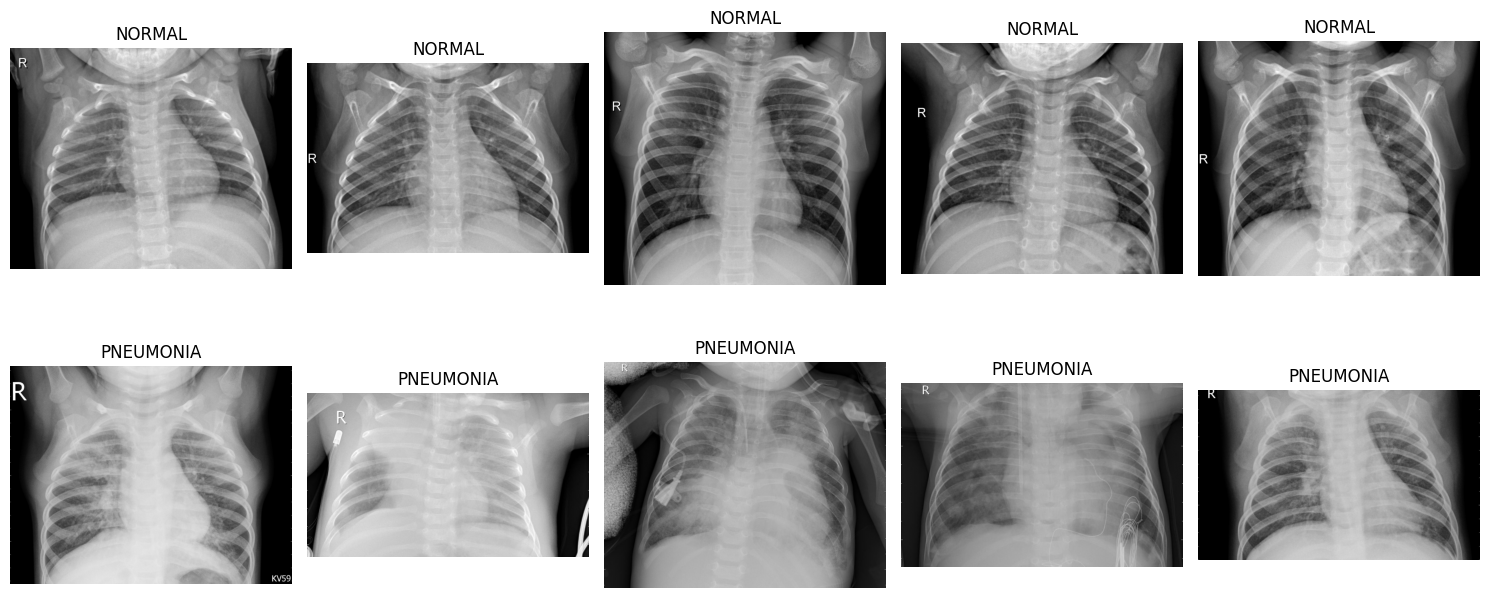

In [16]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

normal_dir = os.path.join(train_dir, "NORMAL")
pneumonia_dir = os.path.join(train_dir, "PNEUMONIA")

normal_images = random.sample(os.listdir(normal_dir), 5)
pneumonia_images = random.sample(os.listdir(pneumonia_dir), 5)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, img_name in enumerate(normal_images):
    img = Image.open(os.path.join(normal_dir, img_name))
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("NORMAL")
    axes[0, i].axis("off")

for i, img_name in enumerate(pneumonia_images):
    img = Image.open(os.path.join(pneumonia_dir, img_name))
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("PNEUMONIA")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [17]:
from collections import Counter

datasets = {
    "Train": train_dir,
    "Test": test_dir,
    "Validation": val_dir
}

total_counts = Counter()

for folder in datasets.values():
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = os.path.join(folder, class_name)

        total_counts[class_name] += sum(
            f.lower().endswith((".jpeg", ".jpg", ".png"))
            for f in os.listdir(class_path)
        )

print("Total NORMAL images:", total_counts["NORMAL"])
print("Total PNEUMONIA images:", total_counts["PNEUMONIA"])
print("Total images:", sum(total_counts.values()))

Total NORMAL images: 1583
Total PNEUMONIA images: 4273
Total images: 5856


In [18]:
from tqdm import tqdm

IMG_SIZE = (224, 224)

output_dir = "/kaggle/working/resized_chest_xray"

datasets = {
    "train": train_dir,
    "test": test_dir,
    "val": val_dir
}

for split, folder in datasets.items():
    for class_name in ["NORMAL", "PNEUMONIA"]:

        input_class_dir = os.path.join(folder, class_name)
        output_class_dir = os.path.join(output_dir, split, class_name)

        os.makedirs(output_class_dir, exist_ok=True)

        image_files = [
            f for f in os.listdir(input_class_dir)
            if f.lower().endswith((".jpeg", ".jpg", ".png"))
        ]

        for img_name in tqdm(image_files, desc=f"{split}/{class_name}"):
            input_path = os.path.join(input_class_dir, img_name)
            output_path = os.path.join(output_class_dir, img_name)

            try:
                with Image.open(input_path) as img:
                    img = img.resize(IMG_SIZE)
                    img.save(output_path)

            except Exception as e:
                print(f"Error processing {input_path}: {e}")

print("All images resized successfully to 224 x 224 pixels.")
print("Resized dataset location:", output_dir)

val/PNEUMONIA: 100%|██████████| 8/8 [00:00<00:00, 94.02it/s]

All images resized successfully to 224 x 224 pixels.
Resized dataset location: /kaggle/working/resized_chest_xray


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.feature import hog, local_binary_pattern
from skimage.feature import graycomatrix, graycoprops
from skimage import exposure

In [21]:
train_dir = os.path.join(output_dir, "train")
test_dir = os.path.join(output_dir, "test")
val_dir = os.path.join(output_dir, "val")

datasets = {
    "train": train_dir,
    "test": test_dir,
    "val": val_dir
}

hog_features = []
lbp_features = []
glcm_features = []

labels = []
splits = []

P = 8
R = 1

glcm_properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation"
]

for split, folder in datasets.items():

    for class_name in ["NORMAL", "PNEUMONIA"]:

        class_path = os.path.join(folder, class_name)

        image_files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpeg", ".jpg", ".png"))
        ]

        for img_name in tqdm(image_files, desc=f"{split}/{class_name}"):

            img_path = os.path.join(class_path, img_name)

            try:
                # Load as grayscale without changing the saved image
                with Image.open(img_path) as img:
                    img = img.convert("L")
                    img = img.resize((224, 224))
                    image = np.array(img)

                # ---------------- HOG ----------------
                hog_feature = hog(
                    image,
                    orientations=9,
                    pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2),
                    block_norm="L2-Hys",
                    feature_vector=True
                )

                # ---------------- LBP ----------------
                lbp_image = local_binary_pattern(
                    image, P, R, method="uniform"
                )

                n_bins = P + 2

                lbp_hist, _ = np.histogram(
                    lbp_image.ravel(),
                    bins=np.arange(0, n_bins + 1),
                    range=(0, n_bins),
                    density=True
                )

                # ---------------- GLCM ----------------
                # Reduce gray levels from 256 to 32
                # to reduce computation and memory
                gray_image = (image // 8).astype(np.uint8)

                glcm = graycomatrix(
                    gray_image,
                    distances=[1],
                    angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                    levels=32,
                    symmetric=True,
                    normed=True
                )

                glcm_feature = []

                for prop in glcm_properties:
                    values = graycoprops(glcm, prop)
                    glcm_feature.extend(values.flatten())

                hog_features.append(hog_feature)
                lbp_features.append(lbp_hist)
                glcm_features.append(glcm_feature)

                labels.append(class_name)
                splits.append(split)

            except Exception as e:
                print(f"Error processing {img_path}: {e}")

print("Feature extraction completed!")
print("Images processed:", len(labels))

val/PNEUMONIA: 100%|██████████| 8/8 [00:00<00:00, 26.56it/s]

Feature extraction completed!
Images processed: 5856


In [22]:
hog_df = pd.DataFrame(hog_features)
lbp_df = pd.DataFrame(lbp_features)

glcm_columns = [
    f"{prop}_{angle}"
    for prop in glcm_properties
    for angle in ["0", "45", "90", "135"]
]

glcm_df = pd.DataFrame(
    glcm_features,
    columns=glcm_columns
)

hog_df["label"] = labels
lbp_df["label"] = labels
glcm_df["label"] = labels

hog_df["split"] = splits
lbp_df["split"] = splits
glcm_df["split"] = splits

print("HOG shape:", hog_df.shape)
print("LBP shape:", lbp_df.shape)
print("GLCM shape:", glcm_df.shape)

HOG shape: (5856, 26246)
LBP shape: (5856, 12)
GLCM shape: (5856, 22)


In [23]:
print("HOG Features:")
display(hog_df.head())

print("LBP Features:")
display(lbp_df.head())

print("GLCM Features:")
display(glcm_df.head())

HOG Features:


,0,1,2,3,4,5,6,7,8,9,...,26236,26237,26238,26239,26240,26241,26242,26243,label,split
0,0.078216,0.011612,0.040393,0.000000,0.023369,0.000000,0.044065,0.011612,0.029623,0.374119,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,NORMAL,train
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,NORMAL,train
2,0.026631,0.000000,0.109790,0.281677,0.069907,0.007444,0.004708,0.000000,0.000000,0.023302,...,0.0,0.0,0.0,0.003774,0.0,0.0,0.0,0.357773,NORMAL,train
3,0.055538,0.003402,0.013715,0.000000,0.014484,0.000000,0.000000,0.011412,0.134041,0.112860,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,NORMAL,train
4,0.207008,0.000000,0.000000,0.000000,0.015728,0.000000,0.000000,0.015729,0.225862,0.446317,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,NORMAL,train


LBP Features:


,0,1,2,3,4,5,6,7,8,9,label,split
0,0.020647,0.044523,0.035535,0.112923,0.275251,0.256956,0.068758,0.050163,0.070572,0.064672,NORMAL,train
1,0.021903,0.046417,0.037966,0.107362,0.285595,0.193519,0.062659,0.045659,0.134825,0.064094,NORMAL,train
2,0.030054,0.056581,0.045520,0.120097,0.278081,0.165378,0.068758,0.055066,0.104811,0.075654,NORMAL,train
3,0.021704,0.047752,0.039361,0.103715,0.252093,0.178651,0.061304,0.048988,0.183992,0.062440,NORMAL,train
4,0.023736,0.050203,0.043088,0.118044,0.288285,0.183335,0.068240,0.049346,0.113082,0.062640,NORMAL,train


GLCM Features:


,contrast_0,contrast_45,contrast_90,contrast_135,dissimilarity_0,dissimilarity_45,dissimilarity_90,dissimilarity_135,homogeneity_0,homogeneity_45,...,energy_0,energy_45,energy_90,energy_135,correlation_0,correlation_45,correlation_90,correlation_135,label,split
0,1.380005,1.819100,0.783993,1.840315,0.633328,0.772909,0.448471,0.767982,0.737097,0.688472,...,0.135152,0.124563,0.147321,0.125562,0.987955,0.984118,0.993235,0.983933,NORMAL,train
1,1.287716,1.813630,0.859105,1.824227,0.653908,0.810272,0.509009,0.817772,0.726382,0.676486,...,0.148225,0.140006,0.156757,0.140010,0.990066,0.985988,0.993435,0.985905,NORMAL,train
2,2.156650,2.960486,1.380986,3.045145,0.856562,1.032194,0.676509,1.065937,0.668687,0.623447,...,0.126130,0.117838,0.134086,0.116665,0.979729,0.972030,0.987115,0.971229,NORMAL,train
3,1.896521,2.525408,1.071008,2.553641,0.688841,0.824026,0.495696,0.827525,0.732474,0.694374,...,0.180647,0.176047,0.192227,0.176107,0.985005,0.979984,0.991571,0.979760,NORMAL,train
4,2.106362,2.846086,1.373519,3.140481,0.821849,1.017817,0.647862,1.049991,0.681047,0.624538,...,0.124877,0.117300,0.133815,0.116880,0.985100,0.979789,0.990337,0.977699,NORMAL,train


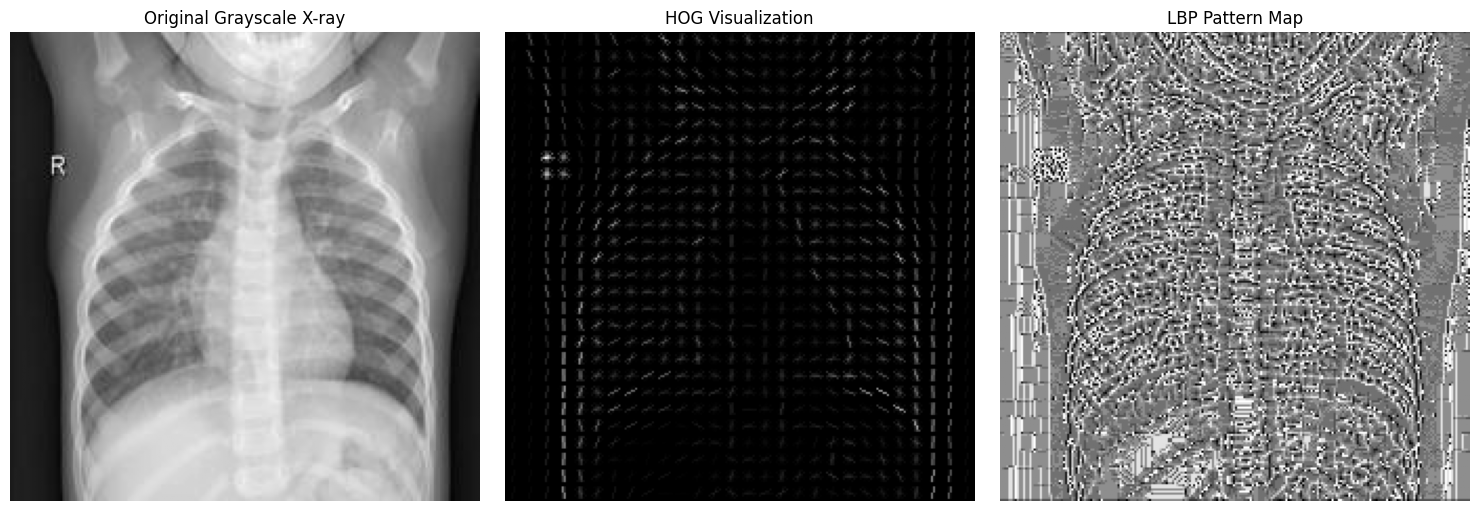

GLCM properties for the sample image:
contrast: 1.4559
dissimilarity: 0.6557
homogeneity: 0.7297
energy: 0.1331
correlation: 0.9873


In [24]:
sample_path = None

for class_name in ["NORMAL", "PNEUMONIA"]:
    class_path = os.path.join(train_dir, class_name)
    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpeg", ".jpg", ".png"))
    ]

    if image_files:
        sample_path = os.path.join(class_path, image_files[0])
        break

with Image.open(sample_path) as img:
    image = np.array(img.convert("L").resize((224, 224)))

# HOG visualization
hog_feature, hog_image = hog(
    image,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

# LBP visualization
lbp_image = local_binary_pattern(
    image, P, R, method="uniform"
)

# GLCM for the sample
gray_image = (image // 8).astype(np.uint8)

glcm = graycomatrix(
    gray_image,
    distances=[1],
    angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
    levels=32,
    symmetric=True,
    normed=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Grayscale X-ray")

axes[1].imshow(
    exposure.rescale_intensity(hog_image, in_range="image"),
    cmap="gray"
)
axes[1].set_title("HOG Visualization")

axes[2].imshow(lbp_image, cmap="gray")
axes[2].set_title("LBP Pattern Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("GLCM properties for the sample image:")
for prop in glcm_properties:
    print(f"{prop}: {graycoprops(glcm, prop).mean():.4f}")

In [25]:
import numpy as np
import pandas as pd

X_hog = hog_df.drop(columns=["label", "split"]).values
X_lbp = lbp_df.drop(columns=["label", "split"]).values
X_glcm = glcm_df.drop(columns=["label", "split"]).values

X = np.concatenate([X_hog, X_lbp, X_glcm], axis=1)

y = hog_df["label"].values
image_splits = hog_df["split"].values

feature_columns = (
    [f"HOG_{i}" for i in range(X_hog.shape[1])] +
    [f"LBP_{i}" for i in range(X_lbp.shape[1])] +
    list(glcm_df.drop(columns=["label", "split"]).columns)
)

feature_df = pd.DataFrame(X, columns=feature_columns)
feature_df["label"] = y
feature_df["split"] = image_splits

print("Feature vector shape:", X.shape)
print("Labels shape:", y.shape)
print("Total features per image:", X.shape[1])

display(feature_df.head())

Feature vector shape: (5856, 26274)
Labels shape: (5856,)
Total features per image: 26274


,HOG_0,HOG_1,HOG_2,HOG_3,HOG_4,HOG_5,HOG_6,HOG_7,HOG_8,HOG_9,...,energy_0,energy_45,energy_90,energy_135,correlation_0,correlation_45,correlation_90,correlation_135,label,split
0,0.078216,0.011612,0.040393,0.000000,0.023369,0.000000,0.044065,0.011612,0.029623,0.374119,...,0.135152,0.124563,0.147321,0.125562,0.987955,0.984118,0.993235,0.983933,NORMAL,train
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.148225,0.140006,0.156757,0.140010,0.990066,0.985988,0.993435,0.985905,NORMAL,train
2,0.026631,0.000000,0.109790,0.281677,0.069907,0.007444,0.004708,0.000000,0.000000,0.023302,...,0.126130,0.117838,0.134086,0.116665,0.979729,0.972030,0.987115,0.971229,NORMAL,train
3,0.055538,0.003402,0.013715,0.000000,0.014484,0.000000,0.000000,0.011412,0.134041,0.112860,...,0.180647,0.176047,0.192227,0.176107,0.985005,0.979984,0.991571,0.979760,NORMAL,train
4,0.207008,0.000000,0.000000,0.000000,0.015728,0.000000,0.000000,0.015729,0.225862,0.446317,...,0.124877,0.117300,0.133815,0.116880,0.985100,0.979789,0.990337,0.977699,NORMAL,train


In [26]:
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [27]:
train_dir = os.path.join(output_dir, "train")
val_dir = os.path.join(output_dir, "val")
test_dir = os.path.join(output_dir, "test")

IMG_SIZE = (224, 224)

class_names = ["NORMAL", "PNEUMONIA"]
class_to_label = {"NORMAL": 0, "PNEUMONIA": 1}

def get_image_paths(folder):
    paths = []
    labels = []

    for class_name in class_names:
        class_path = os.path.join(folder, class_name)

        for filename in os.listdir(class_path):
            if filename.lower().endswith((".jpeg", ".jpg", ".png")):
                paths.append(os.path.join(class_path, filename))
                labels.append(class_to_label[class_name])

    return np.array(paths), np.array(labels)

X_train_paths, y_train = get_image_paths(train_dir)
X_val_paths, y_val = get_image_paths(val_dir)
X_test_paths, y_test = get_image_paths(test_dir)

print("Training images:", len(X_train_paths))
print("Validation images:", len(X_val_paths))
print("Testing images:", len(X_test_paths))
print("Classes: 0 = NORMAL, 1 = PNEUMONIA")

Training images: 5216
Validation images: 16
Testing images: 624
Classes: 0 = NORMAL, 1 = PNEUMONIA


In [28]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=1, expand_animations=False
    )
    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.float32)


def make_dataset(paths, labels, batch_size, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(paths), reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image, num_parallel_calls=tf.data.AUTOTUNE
    )
    dataset = dataset.batch(batch_size)
    return dataset.prefetch(tf.data.AUTOTUNE)

In [29]:
def build_cnn(learning_rate=0.001, dropout_rate=0.3):

    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),

        # First convolutional block
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Second convolutional block
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Third convolutional block
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Classification layers
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [30]:
from itertools import product

# Hyperparameter combinations
param_grid = [
    {"learning_rate": 0.001,  "batch_size": 32, "dropout_rate": 0.3},
    {"learning_rate": 0.0001, "batch_size": 32, "dropout_rate": 0.3},
    {"learning_rate": 0.001,  "batch_size": 64, "dropout_rate": 0.5}
]

# Stratified 3-fold cross-validation
skf = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

results = []

for params in param_grid:
    fold_accuracies = []

    print("\nTesting parameters:", params)

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train_paths, y_train), start=1
    ):
        tf.keras.backend.clear_session()

        # Divide training images into fold training and validation
        fold_train_paths = X_train_paths[train_idx]
        fold_train_labels = y_train[train_idx]

        fold_val_paths = X_train_paths[val_idx]
        fold_val_labels = y_train[val_idx]

        train_ds = make_dataset(
            fold_train_paths,
            fold_train_labels,
            params["batch_size"],
            shuffle=True
        )

        val_ds = make_dataset(
            fold_val_paths,
            fold_val_labels,
            params["batch_size"]
        )

        # Build a fresh model for each fold
        model = build_cnn(
            learning_rate=params["learning_rate"],
            dropout_rate=params["dropout_rate"]
        )

        # Stop early if validation performance stops improving
        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=5,
            callbacks=[early_stop],
            verbose=1
        )

        best_accuracy = max(history.history["val_accuracy"])
        fold_accuracies.append(best_accuracy)

        print(f"Fold {fold} best validation accuracy: "
              f"{best_accuracy:.4f}")

    mean_accuracy = np.mean(fold_accuracies)

    results.append({
        **params,
        "mean_cv_accuracy": mean_accuracy,
        "std_cv_accuracy": np.std(fold_accuracies)
    })

    print(f"Mean CV accuracy: {mean_accuracy:.4f}")

# Compare all configurations
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "mean_cv_accuracy", ascending=False
).reset_index(drop=True)

display(results_df)


Testing parameters: {'learning_rate': 0.001, 'batch_size': 32, 'dropout_rate': 0.3}
Epoch 1/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 519s 5s/step - accuracy: 0.8341 - loss: 0.3479 - val_accuracy: 0.9505 - val_loss: 0.1456
Epoch 2/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 527s 4s/step - accuracy: 0.9488 - loss: 0.1408 - val_accuracy: 0.9212 - val_loss: 0.2225
Epoch 3/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 477s 4s/step - accuracy: 0.9523 - loss: 0.1333 - val_accuracy: 0.9620 - val_loss: 0.1026
Epoch 4/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 512s 4s/step - accuracy: 0.9655 - loss: 0.0936 - val_accuracy: 0.9626 - val_loss: 0.0953
Epoch 5/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 486s 4s/step - accuracy: 0.9687 - loss: 0.0805 - val_accuracy: 0.9661 - val_loss: 0.1049
Fold 1 best validation accuracy: 0.9661
Epoch 1/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 498s 5s/step - accuracy: 0.8763 - loss: 0.3003 - val_accuracy: 0.9569 - val_loss: 0.1124
Epoch 2/5
109/109 ━━━━━━━━━━━━━━━━━━━━ 492s 4s/step - accuracy: 0.9557 - loss: 0.1266 - val_accuracy: 0.963

,learning_rate,batch_size,dropout_rate,mean_cv_accuracy,std_cv_accuracy
0,0.0001,32,0.3,0.967984,0.004554
1,0.0010,64,0.5,0.966642,0.002851
2,0.0010,32,0.3,0.963381,0.002126


In [31]:
# Select the best hyperparameter combination
best_params = results_df.iloc[0]

best_lr = float(best_params["learning_rate"])
best_batch_size = int(best_params["batch_size"])
best_dropout = float(best_params["dropout_rate"])

print("Best hyperparameters:")
print("Learning rate:", best_lr)
print("Batch size:", best_batch_size)
print("Dropout rate:", best_dropout)
print("Mean CV accuracy:", best_params["mean_cv_accuracy"])

# Prepare the complete training and validation datasets
train_ds = make_dataset(
    X_train_paths, y_train, best_batch_size, shuffle=True
)

val_ds = make_dataset(
    X_val_paths, y_val, best_batch_size
)

# Build and train a fresh model
tf.keras.backend.clear_session()

final_model = build_cnn(
    learning_rate=best_lr,
    dropout_rate=best_dropout
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
    verbose=1
)

Best hyperparameters:
Learning rate: 0.0001
Batch size: 32
Dropout rate: 0.3
Mean CV accuracy: 0.9679842988650004
Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 606s 4s/step - accuracy: 0.8635 - loss: 0.3062 - val_accuracy: 0.7500 - val_loss: 0.5632
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 620s 4s/step - accuracy: 0.9546 - loss: 0.1309 - val_accuracy: 0.6875 - val_loss: 0.7765
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 625s 4s/step - accuracy: 0.9588 - loss: 0.1090 - val_accuracy: 0.8125 - val_loss: 0.3690
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 604s 4s/step - accuracy: 0.9670 - loss: 0.0951 - val_accuracy: 0.9375 - val_loss: 0.1952
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 621s 4s/step - accuracy: 0.9709 - loss: 0.0828 - val_accuracy: 0.8125 - val_loss: 0.3959
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 627s 4s/step - accuracy: 0.9741 - loss: 0.0762 - val_accuracy: 0.6875 - val_loss: 0.9003
Epoch 7/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 621s 4s/step - accuracy: 0.9780 - loss: 0.0664 - val_accuracy: 0.6875 - 

20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step
Accuracy: 0.7996794871794872
Precision: 0.7644710578842315
Recall: 0.982051282051282
F1-score: 0.8597081930415263

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.50      0.65       234
   PNEUMONIA       0.76      0.98      0.86       390

    accuracy                           0.80       624
   macro avg       0.85      0.74      0.75       624
weighted avg       0.83      0.80      0.78       624



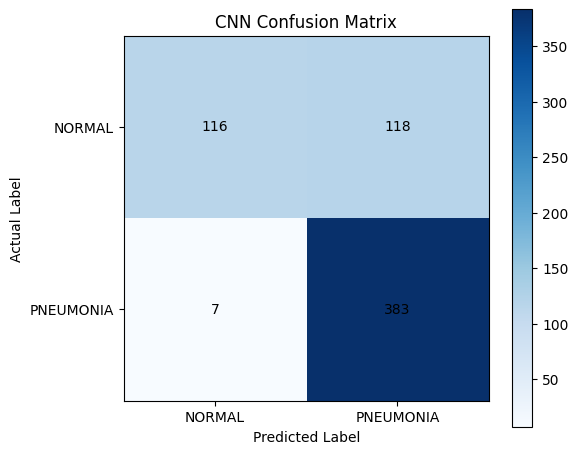

In [32]:
# Prepare the test dataset
test_ds = make_dataset(
    X_test_paths, y_test, best_batch_size
)

# Get predicted probabilities
y_prob = final_model.predict(test_ds).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["NORMAL", "PNEUMONIA"])
plt.yticks([0, 1], ["NORMAL", "PNEUMONIA"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

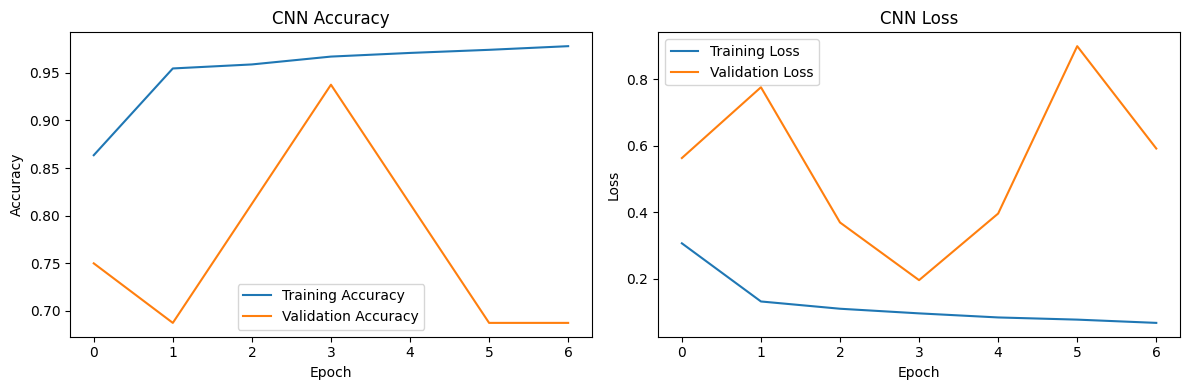

In [33]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_true = y_test

y_prob = final_model.predict(test_ds).ravel()

y_pred = (y_prob >= 0.5).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step


In [35]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

auroc = roc_auc_score(y_true, y_prob)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

display(results.round(4))

,Metric,Score
0,Accuracy,0.7997
1,Precision,0.7645
2,Recall,0.9821
3,F1-score,0.8597
4,AUROC,0.9140


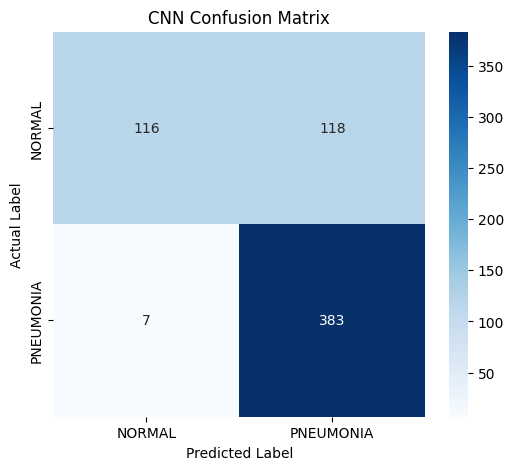

In [37]:
import seaborn as sns
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [38]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      NORMAL     0.9431    0.4957    0.6499       234
   PNEUMONIA     0.7645    0.9821    0.8597       390

    accuracy                         0.7997       624
   macro avg     0.8538    0.7389    0.7548       624
weighted avg     0.8315    0.7997    0.7810       624

